# Supplementary Figure S9g. Neuron-initiated glial paths after excitatory-neuron subsampling

For each excitatory-neuron subsample (100K, 200K, 300K nuclei), colocalization was rerun with the subsampled Exc *cis*-eQTL (other cell types unchanged; *trans* side = *trans*-eGene only). Among loci with both a *cis* and a *trans*-eGene cell-type label whose *cis* and *trans* cell-type sets are disjoint (749, 781 and 808 loci), the heatmaps give the number of loci with *cis*-Exc and each recipient cell type (diagonal Exc-Exc empty by construction; colour limit 0-140 as in the source), and the bar plots give the number of these loci with each cell type on the *cis* or *trans*-eGene side. In the subsample colocalization files the subsampled Exc *cis*-eQTL carries the cell-type field "NA" (e.g. `cis:NA:Exc_n100k_...`); these labels were reassigned to Exc, as in the source code, after checking that every "NA" label is a subsampled-Exc *cis* label. Descriptive counts; no statistical test.

Input: `data/Figure_S9g_subsample_paths.rds`

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_S9g_subsample_paths.rds")
res$cohort
head(res$heatmap)
head(res$bars)

,sample_size,n_both,n_disjoint
,<chr>,<int>,<int>
100K,100K,1075,749
200K,200K,1121,781
300K,300K,1149,808


,sample_size,cis_cell,trans_cell,n_loci,is_diagonal
,<fct>,<chr>,<fct>,<int>,<lgl>
1,100K,Exc,Mic,44,FALSE
2,100K,Exc,Exc,0,TRUE
3,100K,Exc,Inh,58,FALSE
4,100K,Exc,Ast,68,FALSE
5,100K,Exc,Oli,47,FALSE
6,100K,Exc,OPC,79,FALSE


,sample_size,category,cell_type,n_loci
,<fct>,<fct>,<fct>,<dbl>
1,100K,cis-eQTL,Mic,56
2,100K,cis-eQTL,Exc,250
3,100K,cis-eQTL,Inh,220
4,100K,cis-eQTL,Ast,150
5,100K,cis-eQTL,Oli,141
6,100K,cis-eQTL,OPC,48


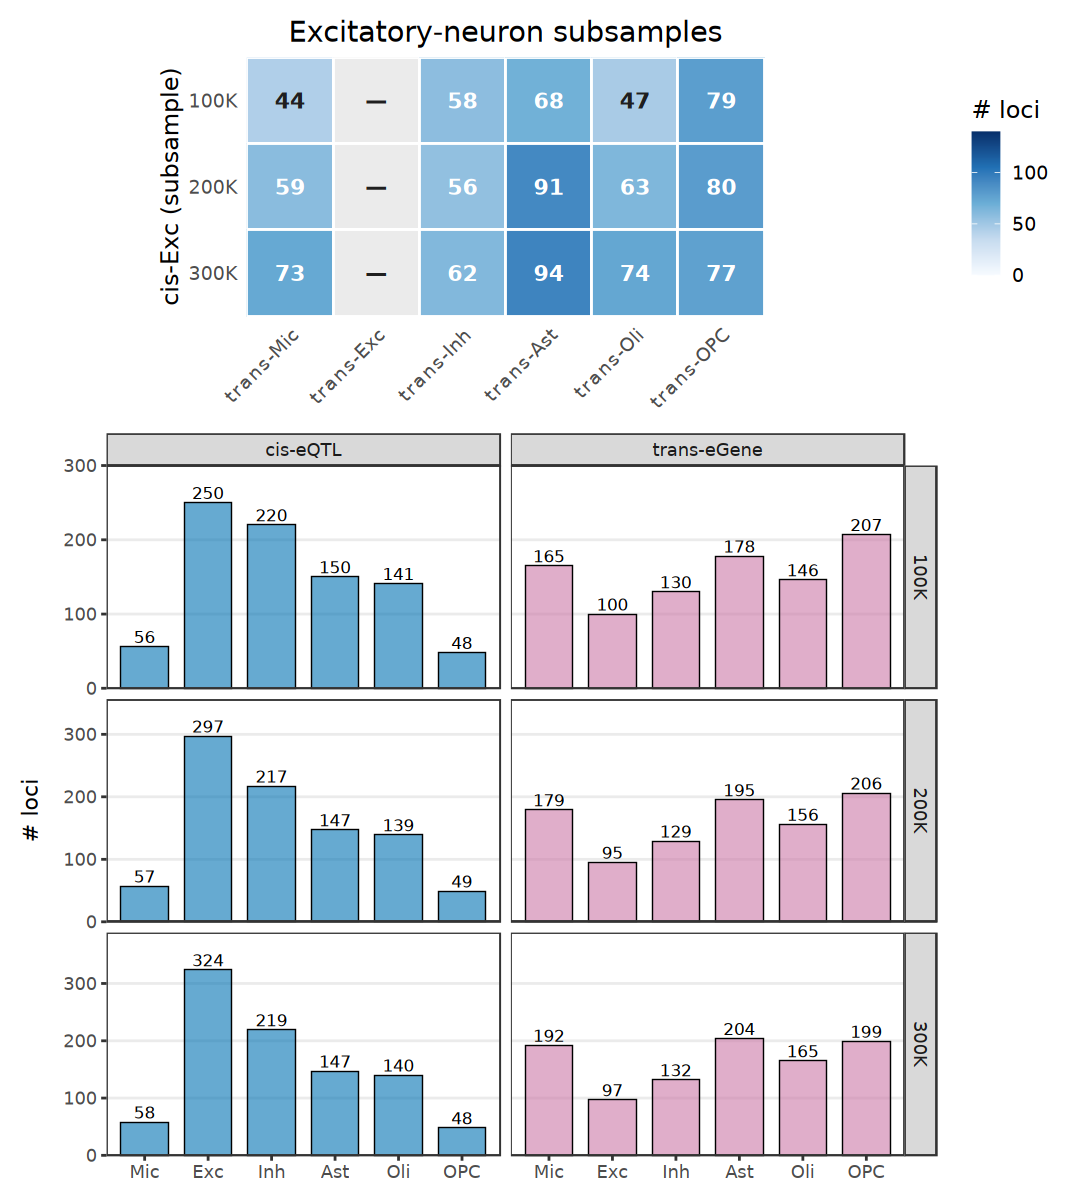

In [2]:
hm <- res$heatmap
hm$fill <- ifelse(hm$is_diagonal, NA, hm$n_loci)
hm$label <- ifelse(hm$is_diagonal, "\u2014", hm$n_loci)
hm$sample_size <- factor(hm$sample_size, levels = rev(levels(hm$sample_size)))

p_heat <- ggplot(hm, aes(x = trans_cell, y = sample_size)) +
  geom_tile(aes(fill = fill), colour = "white", linewidth = 0.6) +
  geom_text(aes(label = label, colour = !is.na(fill) & fill > 0.55 * max(fill, na.rm = TRUE)),
            size = 4.5, fontface = "bold", show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1F1F1F"), guide = "none") +
  scale_fill_gradientn(colours = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"),
                       limits = c(0, 140), na.value = "grey92", name = "# loci") +
  scale_x_discrete(labels = function(x) parse(text = paste0("italic(trans)*'-", x, "'")),
                   expand = c(0, 0)) +
  scale_y_discrete(expand = c(0, 0)) +
  coord_fixed() +
  labs(x = NULL, y = "cis-Exc (subsample)", title = "Excitatory-neuron subsamples") +
  theme_minimal(base_size = 14) +
  theme(panel.grid = element_blank(), plot.title = element_text(hjust = 0.5),
        axis.text.x = element_text(angle = 45, hjust = 1))

p_bar <- ggplot(res$bars, aes(x = cell_type, y = n_loci, fill = category)) +
  geom_col(width = 0.75, alpha = 0.6, colour = "black", linewidth = 0.3) +
  geom_text(aes(label = n_loci), vjust = -0.3, size = 3.4) +
  facet_grid(sample_size ~ category, scales = "free_y") +
  scale_fill_manual(values = c("cis-eQTL" = "#0072B2", "trans-eGene" = "#CC79A7"), guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.2))) +
  labs(x = NULL, y = "# loci") +
  theme_bw(base_size = 13) +
  theme(panel.grid.minor = element_blank(), panel.grid.major.x = element_blank())

options(repr.plot.width = 9, repr.plot.height = 10)
p_heat / p_bar + plot_layout(heights = c(0.6, 1.6))